In [ ]:
%pip install tensorflow tensorflow-datasets scikit-learn

In [10]:
import numpy as np
import tensorflow as tf
import matplotlib.pyplot as plt
import tensorflow_datasets as tfds
from tensorflow.keras import layers, Model
from tensorflow.keras.applications import VGG16
from tensorflow.keras.applications.vgg16 import preprocess_input
from sklearn.model_selection import train_test_split

SEED = 42
np.random.seed(SEED)
tf.random.set_seed(SEED)

In [11]:
# Load Caltech-101
(ds,), info = tfds.load(
    "caltech101",
    split=["train"],
    as_supervised=True,
    with_info=True
)
class_names_all = info.features["label"].names

In [12]:
# Choose five category names present in the dataset
selected_names = ["airplanes", "ant", "camera", "cannon", "chair"]
missing = [name for name in selected_names if name not in class_names_all]
if missing:
    raise ValueError(f"Categories not found: {missing}")

selected_ids = [class_names_all.index(name) for name in selected_names]

# Select, resize, and collect images and labels
images, labels = [], []
for image, label in tfds.as_numpy(ds):
    label = int(label)
    if label in selected_ids:
        image = tf.image.resize(image, (224, 224)).numpy()
        images.append(image)
        labels.append(selected_ids.index(label))

X = np.asarray(images, dtype=np.float32)
y = np.asarray(labels, dtype=np.int32)

# Split into train, validation, and test sets
X_train, X_temp, y_train, y_temp = train_test_split(
    X, y, test_size=0.2, random_state=SEED, stratify=y
)
X_val, X_test, y_val, y_test = train_test_split(
    X_temp, y_temp, test_size=0.5, random_state=SEED, stratify=y_temp
)

In [14]:
# Apply VGG16 preprocessing and one-hot encode labels
def make_dataset(images, labels, training=False, batch_size=16):
    dataset = tf.data.Dataset.from_tensor_slices((images, labels))

    if training:
        dataset = dataset.shuffle(len(images), seed=SEED)

    def prepare(image, label):
        image = preprocess_input(image)
        label = tf.one_hot(label, depth=len(selected_names))
        return image, label

    return (
        dataset.map(prepare, num_parallel_calls=tf.data.AUTOTUNE)
        .batch(batch_size)
        .prefetch(tf.data.AUTOTUNE)
    )

train_ds = make_dataset(X_train, y_train, training=True)
val_ds = make_dataset(X_val, y_val)
test_ds = make_dataset(X_test, y_test)

In [15]:
# VGG16 feature extractor with pretrained layers frozen
base_model = VGG16(
    weights="imagenet",
    include_top=False,
    input_shape=(224, 224, 3)
)
base_model.trainable = False

# Custom classifier
inputs = layers.Input(shape=(224, 224, 3))
x = base_model(inputs, training=False)
x = layers.GlobalAveragePooling2D()(x)
x = layers.Dense(256, activation="relu")(x)
x = layers.Dropout(0.5)(x)
outputs = layers.Dense(len(selected_names), activation="softmax")(x)
model = Model(inputs, outputs)

model.compile(
    optimizer="adam",
    loss="categorical_crossentropy",
    metrics=["accuracy"]
)

In [16]:
# Train and evaluate
model.fit(train_ds, validation_data=val_ds, epochs=5)
_, test_accuracy = model.evaluate(test_ds, verbose=0)
print(f"Test accuracy: {test_accuracy * 100:.2f}%")

Epoch 1/5
8/8 ━━━━━━━━━━━━━━━━━━━━ 24s 3s/step - accuracy: 0.4667 - loss: 5.2412 - val_accuracy: 0.8667 - val_loss: 0.4846
Epoch 2/5
8/8 ━━━━━━━━━━━━━━━━━━━━ 26s 3s/step - accuracy: 0.7917 - loss: 1.3344 - val_accuracy: 0.8667 - val_loss: 0.1703
Epoch 3/5
8/8 ━━━━━━━━━━━━━━━━━━━━ 27s 3s/step - accuracy: 0.9500 - loss: 0.4008 - val_accuracy: 1.0000 - val_loss: 0.0469
Epoch 4/5
8/8 ━━━━━━━━━━━━━━━━━━━━ 36s 5s/step - accuracy: 0.9583 - loss: 0.1460 - val_accuracy: 1.0000 - val_loss: 0.0459
Epoch 5/5
8/8 ━━━━━━━━━━━━━━━━━━━━ 56s 7s/step - accuracy: 0.9750 - loss: 0.0637 - val_accuracy: 1.0000 - val_loss: 0.0098
Test accuracy: 93.33%


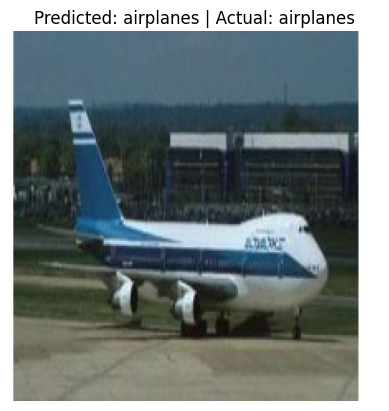

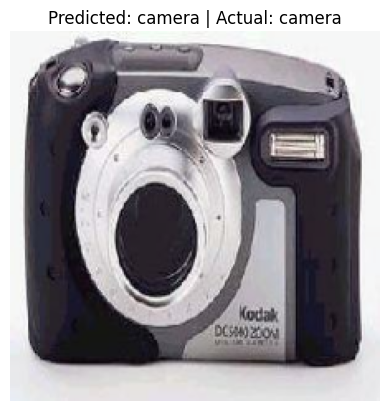

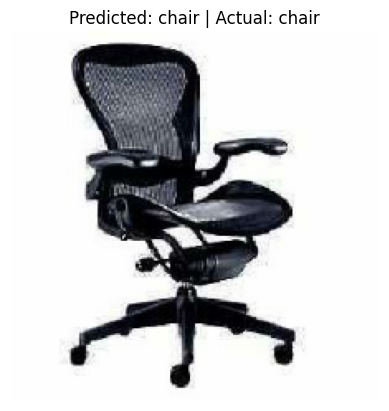

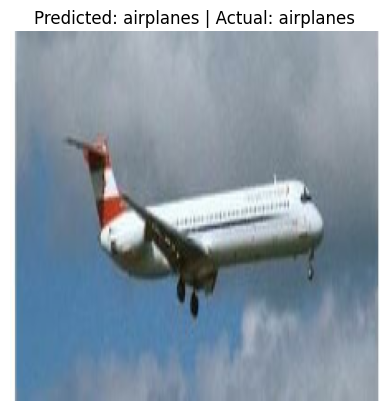

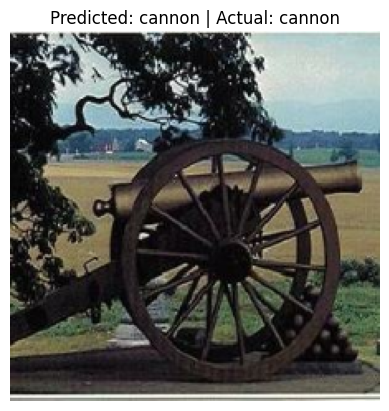

In [17]:
# Predict and display five test images
for images, labels in test_ds.take(1):
    probabilities = model.predict(images[:5], verbose=0)
    predicted = np.argmax(probabilities, axis=1)
    actual = np.argmax(labels.numpy()[:5], axis=1)

    # VGG16 preprocess_input subtracts these channel means (BGR order)
    display_images = images[:5].numpy() + [103.939, 116.779, 123.68]
    display_images = np.clip(display_images[..., ::-1] / 255.0, 0, 1)

    for i in range(len(predicted)):

        plt.imshow(display_images[i])
        plt.title(
            f"Predicted: {selected_names[predicted[i]]} | "
            f"Actual: {selected_names[actual[i]]}"
        )
        plt.axis("off")
        plt.show()